# **Day 88: Project - West Bengal Census Data Analysis**

In this project we use **Pandas** and **Matplotlib** together to study the population of West Bengal's districts.

**Data:** Census 2011 figures for the 19 districts that existed before 2014. Population numbers are from the census tables. Area, literacy and sex ratio are approximate.

**Questions we want to answer:**
1. Which districts are the most crowded (highest density)?
2. How does literacy change between divisions?
3. Is there any relationship between density and literacy?
4. How do North Bengal and South Bengal compare?

**Terms used:**
- **Population density:** People per square km.
- **Literacy rate:** Percentage of people (aged 7 and above) who can read and write.
- **Sex ratio:** Number of females for every 1000 males.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from io import StringIO

csv_text = """district,hq,division,population,area_km2,literacy,sex_ratio,lat,lon
Kolkata,Kolkata,Presidency,4496694,206,86.31,908,22.57,88.36
Howrah,Howrah,Presidency,4850029,1467,83.31,939,22.59,88.31
North 24 Parganas,Barasat,Presidency,10009781,4094,84.06,955,22.72,88.48
South 24 Parganas,Alipore,Presidency,8161961,9960,77.51,956,22.53,88.33
Nadia,Krishnanagar,Presidency,5167600,3927,74.97,947,23.40,88.50
Hooghly,Chinsurah,Burdwan,5519145,3149,81.80,961,22.90,88.39
Bardhaman,Bardhaman,Burdwan,7717563,7024,76.21,945,23.23,87.86
Birbhum,Suri,Burdwan,3502404,4545,70.68,956,23.91,87.53
Purba Medinipur,Tamluk,Medinipur,5095875,4736,87.02,938,22.30,87.92
Paschim Medinipur,Midnapore,Medinipur,5913457,9296,78.00,966,22.42,87.32
Bankura,Bankura,Medinipur,3596674,6882,70.26,957,23.23,87.07
Purulia,Purulia,Medinipur,2930115,6259,64.48,957,23.33,86.36
Murshidabad,Baharampur,Malda,7103807,5324,66.59,958,24.10,88.25
Malda,English Bazar,Malda,3988845,3733,61.73,944,25.00,88.14
Uttar Dinajpur,Raiganj,Malda,3007134,3140,59.07,939,25.62,88.12
Dakshin Dinajpur,Balurghat,Malda,1676276,2219,72.82,956,25.22,88.77
Jalpaiguri,Jalpaiguri,Jalpaiguri,3872846,6227,73.25,954,26.52,88.72
Darjeeling,Darjeeling,Jalpaiguri,1846823,3149,79.56,970,27.04,88.27
Cooch Behar,Cooch Behar,Jalpaiguri,2819086,3387,74.78,942,26.32,89.45
"""
df = pd.read_csv(StringIO(csv_text))
df["density"] = (df["population"] / df["area_km2"]).round()
df["region"] = np.where(df["division"].isin(["Malda", "Jalpaiguri"]), "North Bengal", "South Bengal")

print(df.shape)
print(f"Total population: {df['population'].sum():,}")
df.head()

(19, 11)
Total population: 91,276,115


,district,hq,division,population,area_km2,literacy,sex_ratio,lat,lon,density,region
0,Kolkata,Kolkata,Presidency,4496694,206,86.31,908,22.57,88.36,21829.0,South Bengal
1,Howrah,Howrah,Presidency,4850029,1467,83.31,939,22.59,88.31,3306.0,South Bengal
2,North 24 Parganas,Barasat,Presidency,10009781,4094,84.06,955,22.72,88.48,2445.0,South Bengal
3,South 24 Parganas,Alipore,Presidency,8161961,9960,77.51,956,22.53,88.33,819.0,South Bengal
4,Nadia,Krishnanagar,Presidency,5167600,3927,74.97,947,23.40,88.50,1316.0,South Bengal


The total, 91,276,115, matches the official Census 2011 population of West Bengal. So the population column is correct.

## **Question 1: Which Districts are the Most Crowded?**

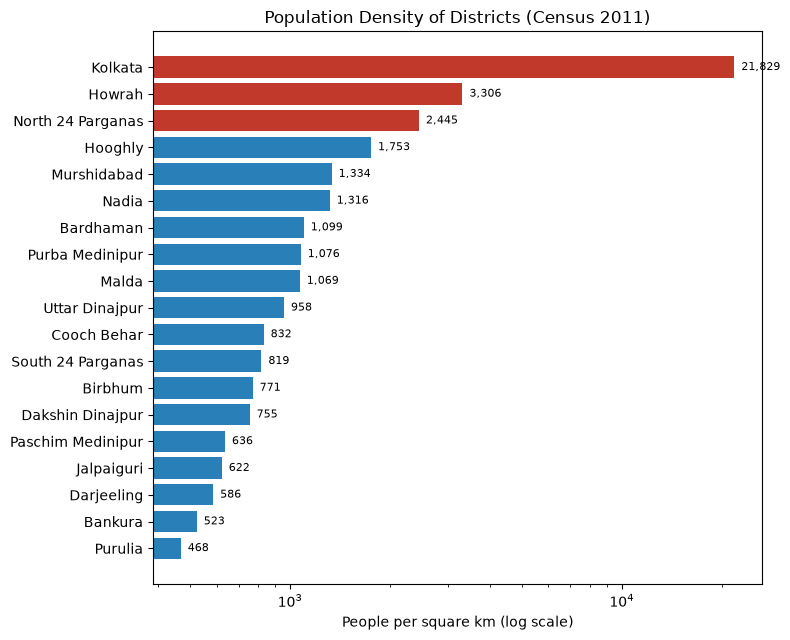

In [2]:
d = df.sort_values("density")

fig, ax = plt.subplots(figsize=(8, 6.5))
colours = ["#c0392b" if v > 2000 else "#2980b9" for v in d["density"]]
ax.barh(d["district"], d["density"], color=colours)
ax.set_xscale("log")
ax.set_xlabel("People per square km (log scale)")
ax.set_title("Population Density of Districts (Census 2011)")
for i, v in enumerate(d["density"]):
    ax.text(v * 1.05, i, f"{v:,.0f}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

Kolkata (about 21,800 people per square km) is so far above the others that we had to use a **log scale**. On a normal scale, all the other bars would look tiny.

## **Question 2: Literacy by Division**
We use a **population-weighted** average. A simple average would give small Dakshin Dinajpur the same importance as huge North 24 Parganas, which would be misleading.

In [3]:
division = df.groupby("division").apply(
    lambda g: pd.Series({
        "districts": len(g),
        "population": g["population"].sum(),
        "literacy": round(np.average(g["literacy"], weights=g["population"]), 1),
    }), include_groups=False
).sort_values("literacy", ascending=False)
division

,districts,population,literacy
division,,,
Presidency,5.0,32686065.0,81.2
Burdwan,3.0,16739112.0,76.9
Medinipur,4.0,17536121.0,76.8
Jalpaiguri,3.0,8538755.0,75.1
Malda,4.0,15776062.0,64.6


## **Question 3: Density vs Literacy**
**Correlation** is a number from -1 to +1 that shows how strongly two things move together:
- close to **+1**: when one goes up, the other also goes up
- close to **0**: no clear relationship
- close to **-1**: when one goes up, the other goes down

In [4]:
df[["density", "literacy", "sex_ratio", "population"]].corr().round(2)

,density,literacy,sex_ratio,population
density,1.00,0.40,-0.77,0.03
literacy,0.40,1.00,-0.20,0.36
sex_ratio,-0.77,-0.20,1.00,0.02
population,0.03,0.36,0.02,1.00


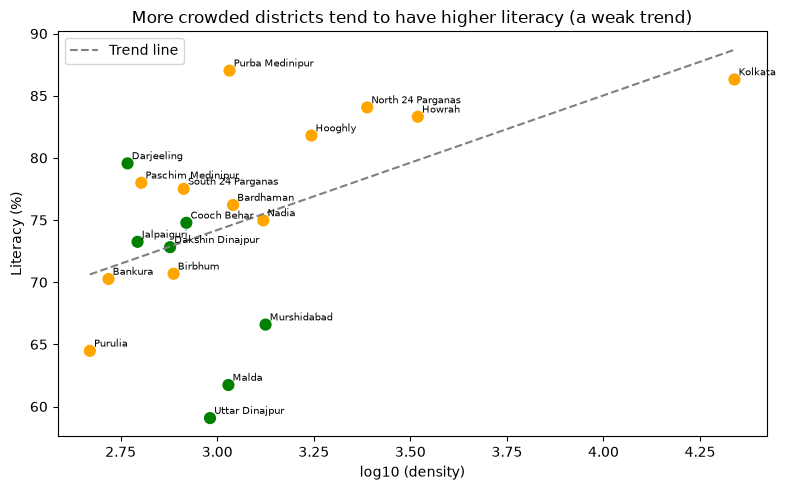

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.log10(df["density"])
colours = np.where(df["region"] == "North Bengal", "green", "orange")
ax.scatter(x, df["literacy"], c=colours, s=60)

slope, intercept = np.polyfit(x, df["literacy"], 1)          # Best-fit straight line
xs = np.linspace(x.min(), x.max(), 10)
ax.plot(xs, slope * xs + intercept, "--", color="gray", label="Trend line")

for _, r in df.iterrows():
    ax.annotate(r["district"], (np.log10(r["density"]), r["literacy"]), fontsize=7,
                xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("log10 (density)")
ax.set_ylabel("Literacy (%)")
ax.set_title("More crowded districts tend to have higher literacy (a weak trend)")
ax.legend()
plt.tight_layout()
plt.show()

There is a **positive but weak** relationship. Remember: **correlation does not mean cause**. Cities have more schools **and** more people, so a third factor (**urbanisation**) probably explains both.

## **Question 4: North Bengal vs South Bengal**

In [6]:
region = df.groupby("region").agg(districts=("district", "count"),
                                  population=("population", "sum"),
                                  area=("area_km2", "sum"))
region["population_%"] = (region["population"] / region["population"].sum() * 100).round(1)
region["area_%"] = (region["area"] / region["area"].sum() * 100).round(1)
region["density"] = (region["population"] / region["area"]).round()
region

,districts,population,area,population_%,area_%,density
region,,,,,,
North Bengal,7,24314817,27179,26.6,30.6,895.0
South Bengal,12,66961298,61545,73.4,69.4,1088.0


## **A Simple Map from Coordinates**
We do not have district boundary shapes here, but we can place each district headquarters at its **latitude and longitude**. The bubble size shows the population, and the colour shows literacy. Even this simple plot looks like the shape of West Bengal.

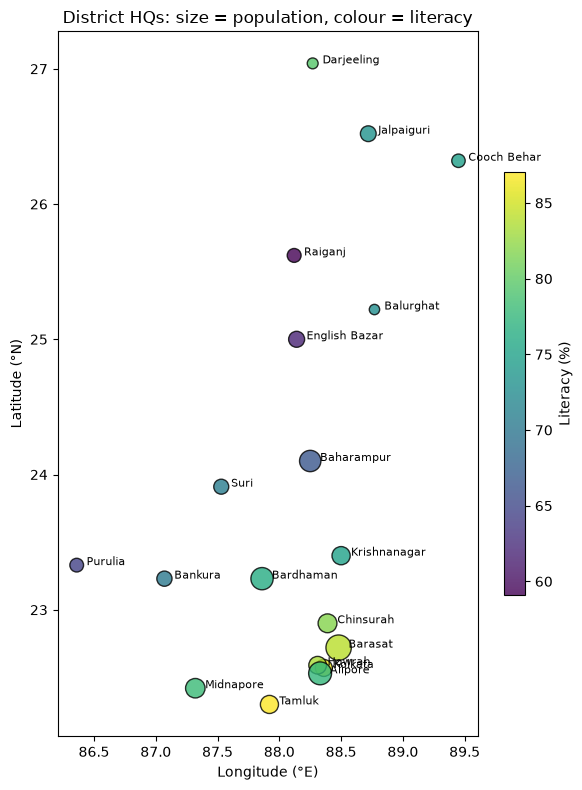

In [7]:
fig, ax = plt.subplots(figsize=(6, 8))
sc = ax.scatter(df["lon"], df["lat"], s=df["population"] / 30000, c=df["literacy"],
                cmap="viridis", alpha=0.8, edgecolor="black")
for _, r in df.iterrows():
    ax.text(r["lon"] + 0.08, r["lat"], r["hq"], fontsize=8)
fig.colorbar(sc, ax=ax, label="Literacy (%)", shrink=0.6)
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title("District HQs: size = population, colour = literacy")
ax.set_aspect(1 / np.cos(np.radians(24)))      # Correct the stretching of degrees at this latitude
plt.tight_layout()
plt.show()

- `set_aspect(1 / cos(24°))`: One degree of longitude is **shorter** than one degree of latitude (except at the equator). This line corrects the shape so the map is not stretched. We will learn why on Day 90.

## **Findings**
1. Kolkata is extremely dense. Howrah and North 24 Parganas come next.
2. **Purba Medinipur** has the highest literacy (87%), even higher than Kolkata. Uttar Dinajpur and Malda are the lowest.
3. Density and literacy have a weak positive relationship, probably through urbanisation.
4. North Bengal (as grouped here) has a smaller share of the population than of the area, so it is less dense.